__Question 01: CLO 5: Python fundamentals, data structures, classes and memory usage (Lab 01, 02). 06 Marks__


In [1]:
import tracemalloc
import gc

records = [
    (101, "Ali", 78),
    (102, "Sara", 91),
    (103, "Usman", 49),
    (104, "Hina", 66),
    (105, "Bilal", 85),
    (106, "Zara", 105),
    (107, "Ahmed", 55),
    (108, "Ayesha", 72)
]

def get_grade(marks):
    if marks < 0 or marks > 100:
        return "Invalid"
    elif marks >= 91:
        return "A"
    elif marks >= 81:
        return "B"
    elif marks >= 71:
        return "C"
    elif marks >= 61:
        return "D"
    elif marks >= 50:
        return "E"
    else:
        return "F"


for student_id, name, marks in records:
    print(student_id, name, marks, get_grade(marks))

print()


class Student:
    def __init__(self, student_id, name, marks):
        self.student_id = student_id
        self.name = name
        self.marks = marks

    def grade(self):
        return get_grade(self.marks)


students = {}

for student_id, name, marks in records:
    if 0 <= marks <= 100:
        students[student_id] = Student(student_id, name, marks)


for student in students.values():
    print(student.__dict__, "Grade:", student.grade())

print()


unique_grades = {student.grade() for student in students.values()}
print("Unique grades:", unique_grades)

grade_counts = {}
for student in students.values():
    grade = student.grade()
    grade_counts[grade] = grade_counts.get(grade, 0) + 1

print("Grade counts:", grade_counts)

topper = max(students.values(), key=lambda student: student.marks)
print("Topper:", topper.name, topper.marks)
print()



class SlimStudent:
    __slots__ = ("student_id", "name", "marks")

    def __init__(self, student_id, name, marks):
        self.student_id = student_id
        self.name = name
        self.marks = marks

    def grade(self):
        return get_grade(self.marks)


def measure_memory(student_class):
    gc.collect()
    tracemalloc.start()

    objects = [
        student_class(i, f"Student {i}", i % 101)
        for i in range(100_000)
    ]

    current, peak = tracemalloc.get_traced_memory()
    tracemalloc.stop()

    del objects
    gc.collect()

    return current, peak


student_current, student_peak = measure_memory(Student)
slim_current, slim_peak = measure_memory(SlimStudent)

reduction = ((student_peak - slim_peak) / student_peak) * 100

print("Student:")
print(f"Current memory: {student_current / (1024 ** 2):.2f} MB")
print(f"Peak memory:    {student_peak / (1024 ** 2):.2f} MB")

print("\nSlimStudent:")
print(f"Current memory: {slim_current / (1024 ** 2):.2f} MB")
print(f"Peak memory:    {slim_peak / (1024 ** 2):.2f} MB")

print(f"\nReduction in peak memory: {reduction:.2f}%")

101 Ali 78 C
102 Sara 91 A
103 Usman 49 F
104 Hina 66 D
105 Bilal 85 B
106 Zara 105 Invalid
107 Ahmed 55 E
108 Ayesha 72 C

{'student_id': 101, 'name': 'Ali', 'marks': 78} Grade: C
{'student_id': 102, 'name': 'Sara', 'marks': 91} Grade: A
{'student_id': 103, 'name': 'Usman', 'marks': 49} Grade: F
{'student_id': 104, 'name': 'Hina', 'marks': 66} Grade: D
{'student_id': 105, 'name': 'Bilal', 'marks': 85} Grade: B
{'student_id': 107, 'name': 'Ahmed', 'marks': 55} Grade: E
{'student_id': 108, 'name': 'Ayesha', 'marks': 72} Grade: C

Unique grades: {'E', 'D', 'B', 'F', 'C', 'A'}
Grade counts: {'C': 2, 'A': 1, 'F': 1, 'D': 1, 'B': 1, 'E': 1}
Topper: Sara 91

Student:
Current memory: 18.11 MB
Peak memory:    18.11 MB

SlimStudent:
Current memory: 14.29 MB
Peak memory:    14.29 MB

Reduction in peak memory: 21.09%


__Question 02: CLO 5: Data preprocessing, Decision Tree training, pruning and evaluation (Lab 04). 09 Marks__


First five rows:
   PassengerId  Pclass     Sex   Age  SibSp  Parch    Fare Embarked  Survived
0           13       3    male  24.0      3      0    8.87        S         0
1            4       1    male   4.0      0      0   92.34        C         1
2           99       1  female  27.0      1      0  100.30        S         1
3            7       1    male   NaN      1      0   83.55        S         1
4          143       1  female  32.0      0      1  156.80        S         1

Shape: (156, 9)

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 156 entries, 0 to 155
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  156 non-null    int64  
 1   Pclass       156 non-null    int64  
 2   Sex          156 non-null    object 
 3   Age          142 non-null    float64
 4   SibSp        156 non-null    int64  
 5   Parch        156 non-null    int64  
 6   Fare         156 non

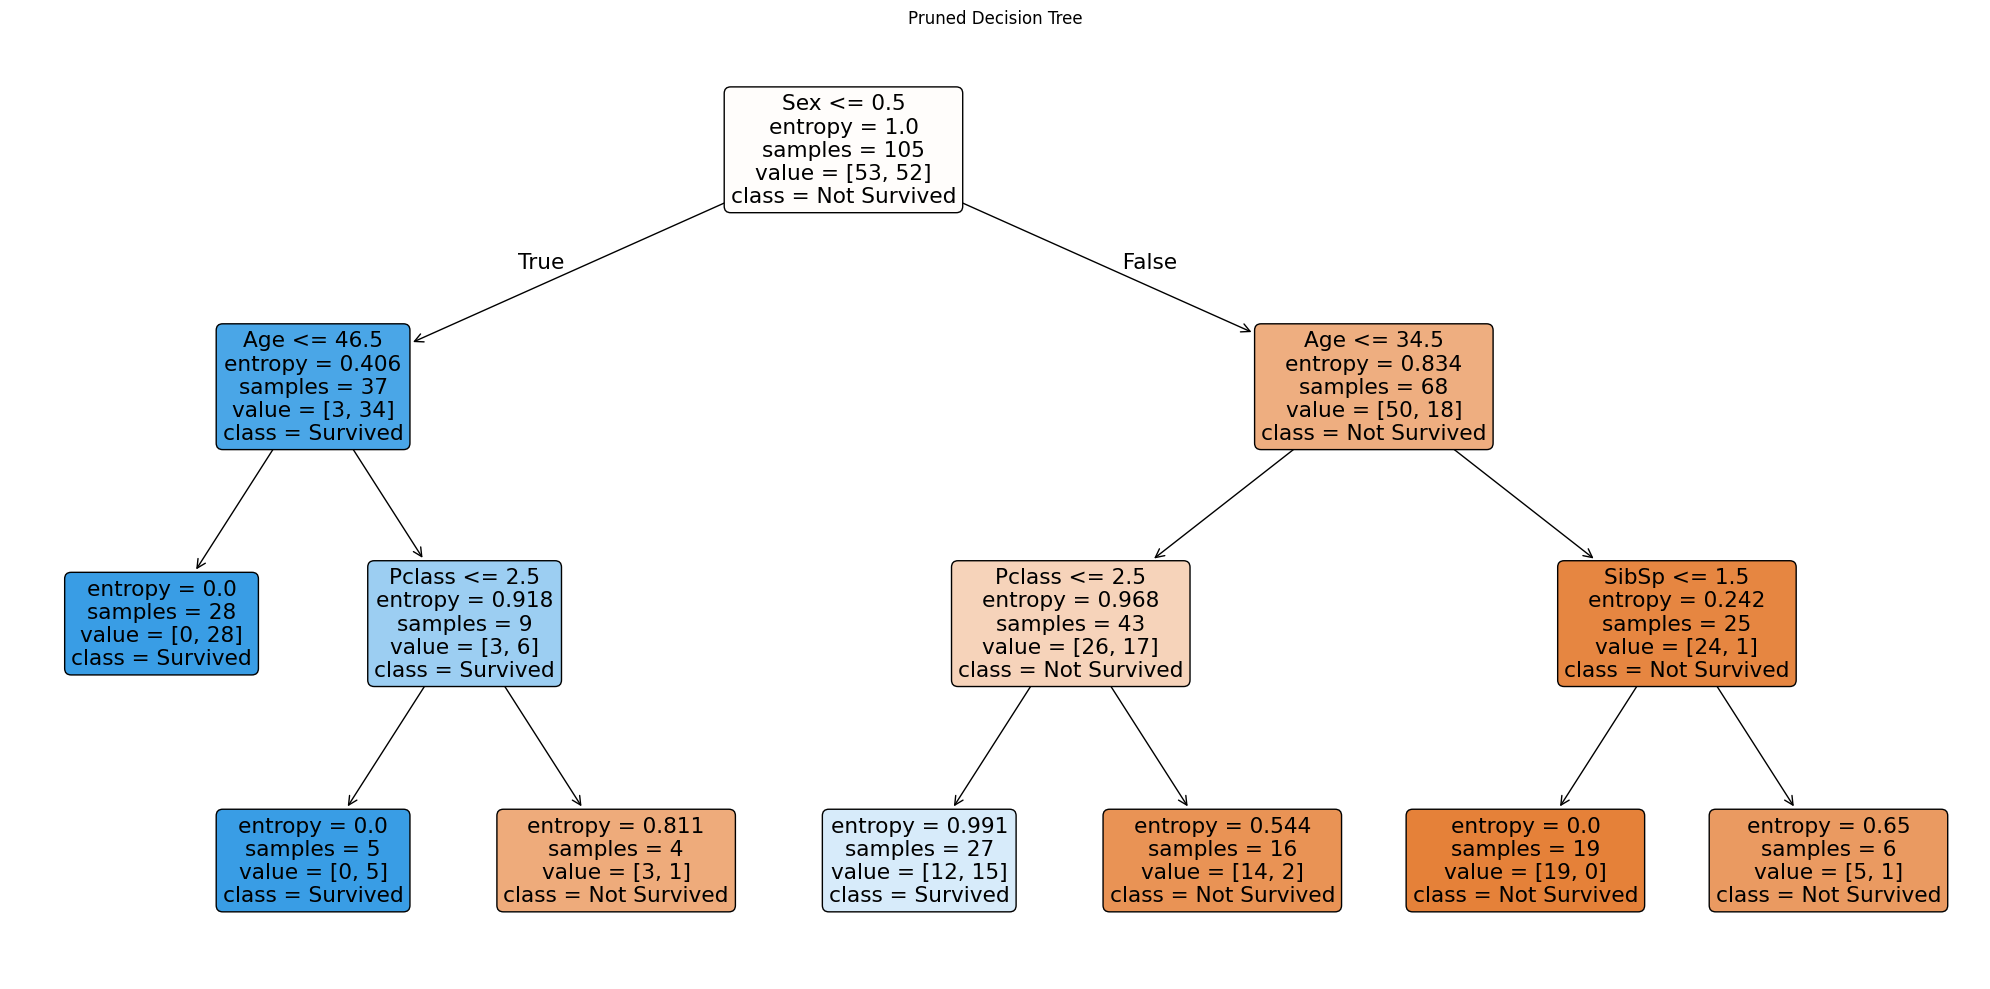


Prediction for the given passenger: Survives


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score


df = pd.read_csv("passengers.csv")

print("First five rows:")
print(df.head())

print("\nShape:", df.shape)

print("\nData types and non-null counts:")
df.info()

print("\nMissing values in each column:")
print(df.isnull().sum())


print("\nNumber of duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates().copy()

df = df.drop(columns=["PassengerId"])

df["Sex"] = df["Sex"].astype("string").str.strip().str.lower()
df["Embarked"] = df["Embarked"].astype("string").str.strip().str.upper()

numeric_columns = [
    "Survived", "Pclass", "Age", "SibSp", "Parch", "Fare"
]

for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

df.loc[df["Fare"] < 0, "Fare"] = np.nan

df["Age"] = df["Age"].fillna(df["Age"].median())
df["Fare"] = df["Fare"].fillna(df["Fare"].median())

df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])

print("\nMissing values after preprocessing:")
print(df.isnull().sum())


sex_encoder = LabelEncoder()
embarked_encoder = LabelEncoder()

df["Sex"] = sex_encoder.fit_transform(df["Sex"])
df["Embarked"] = embarked_encoder.fit_transform(df["Embarked"])

X = df.drop(columns=["Survived"])
y = df["Survived"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=1,
    stratify=y
)

print("\nDataset shapes:")
print("X_train:", X_train.shape)
print("X_test: ", X_test.shape)
print("y_train:", y_train.shape)
print("y_test: ", y_test.shape)


unpruned_tree = DecisionTreeClassifier(random_state=1)

pruned_tree = DecisionTreeClassifier(
    criterion="entropy",
    max_depth=3,
    random_state=1
)

unpruned_tree.fit(X_train, y_train)
pruned_tree.fit(X_train, y_train)

results = pd.DataFrame({
    "Model": ["Unpruned Decision Tree", "Pruned Decision Tree"],
    "Training Accuracy": [
        accuracy_score(y_train, unpruned_tree.predict(X_train)),
        accuracy_score(y_train, pruned_tree.predict(X_train))
    ],
    "Testing Accuracy": [
        accuracy_score(y_test, unpruned_tree.predict(X_test)),
        accuracy_score(y_test, pruned_tree.predict(X_test))
    ]
})

print("\nModel accuracies:")
print(results.to_string(index=False))


plt.figure(figsize=(20, 10))

plot_tree(
    pruned_tree,
    feature_names=X.columns,
    class_names=["Not Survived", "Survived"],
    filled=True,
    rounded=True
)

plt.title("Pruned Decision Tree")
plt.tight_layout()
plt.show()


passenger = pd.DataFrame([{
    "Pclass": 2,
    "Sex": sex_encoder.transform(["female"])[0],
    "Age": 8,
    "SibSp": 1,
    "Parch": 1,
    "Fare": 25,
    "Embarked": embarked_encoder.transform(["S"])[0]
}])

passenger = passenger[X.columns]

prediction = pruned_tree.predict(passenger)[0]

print(
    "\nPrediction for the given passenger:",
    "Survives" if prediction == 1 else "Does not survive"
)

__Question 03: CLO 5: Text classification using a Multinomial Naïve Bayes pipeline (Lab 05). 10 Marks__


Shape before cleaning: (186, 3)
Shape after cleaning: (174, 2)

Class distribution:
Category
Billing      59
Delivery     58
Technical    57
Name: count, dtype: int64


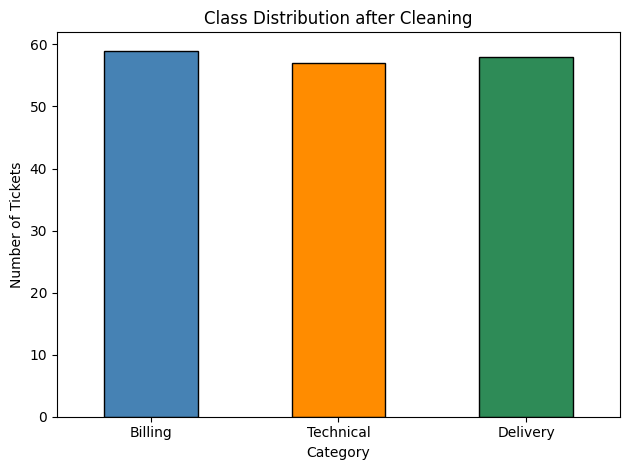


TF-IDF testing accuracy: 0.9091


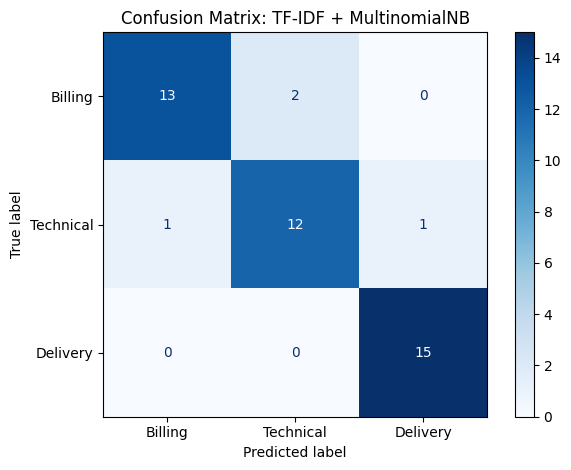


TF-IDF Classification Report:
              precision    recall  f1-score   support

     Billing       0.93      0.87      0.90        15
   Technical       0.86      0.86      0.86        14
    Delivery       0.94      1.00      0.97        15

    accuracy                           0.91        44
   macro avg       0.91      0.91      0.91        44
weighted avg       0.91      0.91      0.91        44

Category predicted least accurately: Technical (lowest recall = 0.8571 )

Model comparison:
                          Model  Accuracy  Macro F1-score
         TF-IDF + MultinomialNB    0.9091          0.9071
CountVectorizer + MultinomialNB    0.8864          0.8842

Better-performing pipeline: TF-IDF + MultinomialNB

Predictions:

Text: I was charged twice and need a refund
Predicted category: Billing
Probability: 0.5445 (54.45%)

Text: The app crashes on the login screen
Predicted category: Technical
Probability: 0.8247 (82.47%)

Text: My parcel is late and tracking shows no updat

In [3]:
import re
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)


df = pd.read_csv("support_tickets.csv")

print("Shape before cleaning:", df.shape)

df = df.drop_duplicates()

df = df.drop(columns=["ID"], errors="ignore")

df["Ticket_Text"] = (
    df["Ticket_Text"]
    .fillna("")
    .astype(str)
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

df = df[df["Ticket_Text"].ne("")]

df["Category"] = (
    df["Category"]
    .fillna("")
    .astype(str)
    .str.strip()
    .str.lower()
    .str.title()
)

valid_categories = ["Billing", "Technical", "Delivery"]
df = df[df["Category"].isin(valid_categories)]

df = df.drop_duplicates(subset=["Ticket_Text", "Category"]).reset_index(drop=True)

print("Shape after cleaning:", df.shape)
print("\nClass distribution:")
print(df["Category"].value_counts())

class_counts = df["Category"].value_counts().reindex(valid_categories, fill_value=0)

class_counts.plot(
    kind="bar",
    color=["steelblue", "darkorange", "seagreen"],
    edgecolor="black"
)
plt.title("Class Distribution after Cleaning")
plt.xlabel("Category")
plt.ylabel("Number of Tickets")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


X = df["Ticket_Text"]
y = df["Category"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=0,
    stratify=y
)

tfidf_model = make_pipeline(
    TfidfVectorizer(stop_words="english"),
    MultinomialNB()
)

tfidf_model.fit(X_train, y_train)
tfidf_predictions = tfidf_model.predict(X_test)

tfidf_accuracy = accuracy_score(y_test, tfidf_predictions)

print("\nTF-IDF testing accuracy:", round(tfidf_accuracy, 4))


ConfusionMatrixDisplay.from_predictions(
    y_test,
    tfidf_predictions,
    labels=valid_categories,
    cmap="Blues",
    values_format="d"
)
plt.title("Confusion Matrix: TF-IDF + MultinomialNB")
plt.tight_layout()
plt.show()

print("\nTF-IDF Classification Report:")
print(
    classification_report(
        y_test,
        tfidf_predictions,
        labels=valid_categories,
        zero_division=0
    )
)

report = classification_report(
    y_test,
    tfidf_predictions,
    labels=valid_categories,
    output_dict=True,
    zero_division=0
)

least_accurate_category = min(
    valid_categories,
    key=lambda category: report[category]["recall"]
)

print(
    "Category predicted least accurately:",
    least_accurate_category,
    "(lowest recall =",
    round(report[least_accurate_category]["recall"], 4),
    ")"
)


count_model = make_pipeline(
    CountVectorizer(stop_words="english"),
    MultinomialNB()
)

count_model.fit(X_train, y_train)
count_predictions = count_model.predict(X_test)

count_accuracy = accuracy_score(y_test, count_predictions)

tfidf_macro_f1 = f1_score(
    y_test,
    tfidf_predictions,
    average="macro"
)

count_macro_f1 = f1_score(
    y_test,
    count_predictions,
    average="macro"
)

comparison = pd.DataFrame({
    "Model": [
        "TF-IDF + MultinomialNB",
        "CountVectorizer + MultinomialNB"
    ],
    "Accuracy": [
        tfidf_accuracy,
        count_accuracy
    ],
    "Macro F1-score": [
        tfidf_macro_f1,
        count_macro_f1
    ]
})

print("\nModel comparison:")
print(comparison.round(4).to_string(index=False))

best_index = comparison.sort_values(
    by=["Macro F1-score", "Accuracy"],
    ascending=False
).index[0]

best_model_name = comparison.loc[best_index, "Model"]

print("\nBetter-performing pipeline:", best_model_name)


def clean_text(text):
    """Convert input to lowercase and normalize its whitespace."""
    if pd.isna(text):
        return ""

    text = str(text).lower()
    text = re.sub(r"\s+", " ", text).strip()
    return text


def predict_category(text, model):
    """Return the predicted category and the probability assigned to that predicted category."""
    cleaned_text = clean_text(text)

    if not cleaned_text:
        raise ValueError("The input text cannot be missing or blank.")

    predicted_category = model.predict([cleaned_text])[0]
    probabilities = model.predict_proba([cleaned_text])[0]

    class_position = list(model.classes_).index(predicted_category)
    predicted_probability = probabilities[class_position]

    return predicted_category, predicted_probability


best_model = tfidf_model if best_index == 0 else count_model

test_messages = [
    "I was charged twice and need a refund",
    "The app crashes on the login screen",
    "My parcel is late and tracking shows no update"
]

print("\nPredictions:")
for message in test_messages:
    category, probability = predict_category(message, best_model)

    print(f"\nText: {message}")
    print(f"Predicted category: {category}")
    print(f"Probability: {probability:.4f} ({probability:.2%})")